# Lambda-value sweep study

## 1. Goal and experimental design

We sweep ten fixed lambda values from 0 to 1 across **30 paired algorithm seeds (0-29)** to examine the balance between **spatial contiguity** and **multivariate delineation** across CMiO, North Batten, and synthetic repeated facies. Each seed is reused at every lambda value on the same dataset. The datasets remain fixed, including the synthetic population generated with seed 42. K-means uses seed 42 and 20 initializations throughout, isolating variation across SC-PaCMAP algorithm seeds.

For each manual run, the chosen lambda replaces the inferred lambda in the normal Phase-3 target-share calculation. The graph construction, attraction normalization, and ramp remain unchanged. No extra upper limit is applied to lambda or the resulting spatial share. Lambda 1 is the manual endpoint, not the automatic setting. The seed-averaged inferred automatic lambda is shown as a dashed vertical reference line; no separate automatic-result runs are added.


In [29]:
from __future__ import annotations
import os, sys
from pathlib import Path
from dataclasses import replace
from scipy.stats import t as student_t
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import numba
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
numba.set_num_threads(1)
set_matplotlib_formats('png')

def find_root():
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'sc-pacmap-reproducibility'):
            if (candidate / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file():
                return candidate
    raise FileNotFoundError('Run this notebook from within the SC-PaCMAP project.')

ROOT = find_root()
sys.path.insert(0, str(ROOT / 'code' / 'sc_pacmap'))
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_sc_pacmap
DATA_SEED = 42
KMEANS_SEED = 42
SEEDS = tuple(range(30))
N_NEIGHBORS = 10
LAMBDA_VALUES = np.linspace(0., 1., 10)
SETTINGS = PaCMAPSettings(random_state=SEEDS[0], n_components=2, n_neighbors=N_NEIGHBORS,
                         mn_ratio=.5, fp_ratio=2., learning_rate=1.,
                         num_iters=(100, 100, 250), knn_backend='faiss', verbose=False)
datasets = {}

def prepare_dataset(data, feature_columns, coordinate_columns, label_column, expected_k):
    assert not data[feature_columns + coordinate_columns + [label_column]].isna().any().any()
    features = StandardScaler().fit_transform(data[feature_columns].to_numpy(np.float64)).astype(np.float32)
    coords = data[coordinate_columns].to_numpy(np.float64)
    truth = data[label_column].to_numpy()
    k = int(pd.Series(truth).nunique())
    assert k == expected_k, f'Unexpected label-class count: {k}'
    assert np.isfinite(features).all() and np.isfinite(coords).all()
    # Match the geographic-neighbor evaluation in New_Notebooks.
    neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
    tss = float(np.sum((features - features.mean(0, keepdims=True)) ** 2))
    assert tss > 0
    return dict(features=features, coords=coords, K=k, neighbors=neighbors, tss=tss)

# Notebook-local intervention; restore the production function after every fit.
from unittest.mock import patch
import sc_pacmap as sc_module

def run_fixed_lambda(features, coords, settings, lambda_value):
    lambda_value = float(lambda_value)
    if not np.isfinite(lambda_value) or not 0.0 <= lambda_value <= 1.0:
        raise ValueError('Lambda must be finite and lie in [0, 1].')
    automatic_share = sc_module._automatic_target_share
    def fixed_lambda_share(inferred_lambda, *args):
        return automatic_share(lambda_value, *args)
    with patch.object(sc_module, '_automatic_target_share', fixed_lambda_share):
        return run_sc_pacmap(features, coords, settings, config=SCPaCMAPConfig())

# Diagnostics retain the inferred lambda; record the applied lambda separately.


## 2. Load and prepare the three datasets

### 2.1 CMiO
Use the same 35 geochemical features and full processed population as the results notebook. Coordinates are supplied separately to the spatial graph; features are standardized.

In [30]:
FEATURES = ['Y_PPM', 'V_PPM', 'LA_PPM', 'U_PPM', 'SR_PPM', 'SN_PPM', 'RB_PPM', 'TH_PPM', 'CS_PPM', 'CE_PPM', 'NB_PPM', 'GA_PPM', 'W_PPM', 'HF_PPM', 'TA_PPM', 'ZR_PPM', 'CR_PPM', 'PR_PPM', 'ND_PPM', 'ER_PPM', 'EU_PPM', 'SM_PPM', 'YB_PPM', 'TB_PPM', 'HO_PPM', 'GD_PPM', 'DY_PPM', 'LU_PPM', 'BA_PPM', 'SIO2_WT_PERCENT', 'TIO2_WT_PERCENT', 'NA2O_WT_PERCENT', 'K2O_WT_PERCENT', 'AL2O3_WT_PERCENT', 'TM_PPM']
cmio = pd.read_csv(ROOT / 'data' / 'processed' / 'cmio_sc_pacmap_ready.csv')
datasets['CMiO'] = prepare_dataset(cmio, FEATURES, ['x', 'y', 'z'], 'label_id', 7)

### 2.2 North Batten
Use the processed drillhole population and the same geochemical columns ending in `_PPM` or `_PCT`. The label classes determine the dataset-specific K.

In [31]:
north_batten = pd.read_csv(ROOT / 'data' / 'processed' / 'north_batten_sc_pacmap_ready.csv')
nb_features = [c for c in north_batten.columns if c.endswith(('_PPM', '_PCT'))]
datasets['North Batten'] = prepare_dataset(north_batten, nb_features, ['x', 'y', 'z'], 'label_id', 15)

### 2.3 Synthetic repeated facies
The original benchmark's data generator and constants are included below so this notebook requires no helper script or execution of another notebook. Seed 42 reproduces the same 2,304 samples, 50 features, and four facies.

In [32]:
GRID_SIDE = 48

TILES_PER_SIDE = 4

TILE_SIDE = GRID_SIDE // TILES_PER_SIDE

N_SAMPLES = GRID_SIDE**2

N_FEATURES = 50

KNOWN_CLASS_COUNT = 4

XY_COLUMNS = ["x_m", "y_m"]

LABEL_COLUMN = "truth_facies"

SPATIAL_FEATURES = [f"spatial_{index:02d}" for index in range(1, 11)]

CONFOUNDER_FEATURES = [f"confounder_{index:02d}" for index in range(1, 21)]

NOISE_FEATURES = [f"noise_{index:02d}" for index in range(1, 21)]

FEATURE_COLUMNS = SPATIAL_FEATURES + CONFOUNDER_FEATURES + NOISE_FEATURES

METADATA_COLUMNS = [
    "sample_id",
    *XY_COLUMNS,
    LABEL_COLUMN,
    "facies_id",
    "patch_id",
]

EXPECTED_LABELS = {
    0: "Facies A",
    1: "Facies B",
    2: "Facies C",
    3: "Facies D",
}

def make_synthetic_repeated_facies(
    random_state: int = DATA_SEED,
) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    """Create the repeated-facies benchmark and its plotting-only latent values."""
    # 1. Use one local random generator so the complete dataset is reproducible.
    rng = np.random.default_rng(random_state)

    # 2. Create a 48 x 48 sampling grid, then add about 1 m of coordinate jitter.
    #    Adjacent nominal samples remain 25 m apart, but the layout is not perfectly regular.
    grid_axis = np.arange(GRID_SIDE)
    x_grid, y_grid = np.meshgrid(grid_axis, grid_axis)
    x_index = x_grid.ravel().astype(np.int64)
    y_index = y_grid.ravel().astype(np.int64)
    coordinate_indices = np.column_stack([x_index, y_index]).astype(np.float64)
    coordinate_jitter = rng.normal(0.0, 0.04, size=coordinate_indices.shape)
    coordinates = 25.0 * (coordinate_indices + coordinate_jitter)

    # 3. Divide the grid into sixteen 12 x 12 physical patches.
    tile_x = x_index // TILE_SIDE
    tile_y = y_index // TILE_SIDE
    patch_id = tile_y * TILES_PER_SIDE + tile_x

    # Apply a Latin-square rule. Each facies occurs in four disconnected patches.
    facies_id = (tile_x + tile_y) % KNOWN_CLASS_COUNT

    # 4. Give every facies a balanced three-value signature.
    #    Any two facies differ in exactly two of the three signature values.
    facies_prototype = np.array(
        [
            [-1.0, -1.0, -1.0],  # Facies A
            [-1.0, +1.0, +1.0],  # Facies B
            [+1.0, -1.0, +1.0],  # Facies C
            [+1.0, +1.0, -1.0],  # Facies D
        ],
        dtype=np.float64,
    )

    # Build ten answer-bearing features from the three-value signatures.
    # Features cycle through signature positions 0, 1, 2 while their noise increases.
    spatial_noise_sigma = np.linspace(0.15, 0.95, 10)
    spatial_columns = []
    for feature_index, noise_sigma in enumerate(spatial_noise_sigma):
        prototype_position = feature_index % facies_prototype.shape[1]
        facies_signal = facies_prototype[facies_id, prototype_position]
        measurement_noise = noise_sigma * rng.normal(size=N_SAMPLES)
        spatial_columns.append(facies_signal + measurement_noise)
    spatial_block = np.column_stack(spatial_columns)

    # 5. Draw nuisance values independently for each sample. They have no intended
    #    relationship with facies or location, but their nonlinear structure is strong.
    nuisance_theta = rng.uniform(-np.pi, np.pi, size=N_SAMPLES)
    nuisance_q = rng.normal(size=N_SAMPLES)
    nuisance_radius = 1.0 + 0.18 * rng.normal(size=N_SAMPLES)

    # Name repeated transformations so the twenty confounders are easier to read.
    cos_theta = np.cos(nuisance_theta)
    sin_theta = np.sin(nuisance_theta)
    tanh_q = np.tanh(nuisance_q)
    centered_q_squared = nuisance_q**2 - 1.0

    confounder_basis = np.column_stack(
        [
            # A noisy circular manifold and its second and third harmonics.
            nuisance_radius * cos_theta,
            nuisance_radius * sin_theta,
            np.cos(2.0 * nuisance_theta),
            np.sin(2.0 * nuisance_theta),
            np.cos(3.0 * nuisance_theta),
            np.sin(3.0 * nuisance_theta),
            # Saturating, polynomial, and periodic transforms of q.
            tanh_q,
            centered_q_squared,
            np.sin(1.5 * nuisance_q),
            np.cos(1.5 * nuisance_q),
            # Additive mixtures of the angle and q structures.
            cos_theta + 0.55 * tanh_q,
            sin_theta - 0.55 * tanh_q,
            np.cos(2.0 * nuisance_theta) + 0.35 * centered_q_squared,
            np.sin(2.0 * nuisance_theta) - 0.35 * centered_q_squared,
            # Multiplicative interactions between the angle and q structures.
            tanh_q * cos_theta,
            tanh_q * sin_theta,
            centered_q_squared * cos_theta,
            centered_q_squared * sin_theta,
            # Two final nonlinear combinations.
            np.sin(nuisance_theta + nuisance_q),
            np.cos(nuisance_theta - nuisance_q),
        ]
    )
    confounder_noise = rng.normal(0.0, 0.12, size=confounder_basis.shape)
    confounder_block = confounder_basis + confounder_noise

    # 6. Add twenty completely independent distractor features.
    independent_block = rng.normal(size=(N_SAMPLES, 20))

    # 7. Join the three feature blocks in their documented 10 + 20 + 20 order.
    feature_matrix = np.column_stack(
        [spatial_block, confounder_block, independent_block]
    )
    assert feature_matrix.shape == (N_SAMPLES, N_FEATURES)

    # Keep labels and locations as metadata; they are not part of FEATURE_COLUMNS.
    metadata = pd.DataFrame(
        {
            "sample_id": [f"S{index:04d}" for index in range(N_SAMPLES)],
            "x_m": coordinates[:, 0],
            "y_m": coordinates[:, 1],
            LABEL_COLUMN: [EXPECTED_LABELS[value] for value in facies_id],
            "facies_id": facies_id,
            "patch_id": patch_id,
        }
    )
    feature_data = pd.DataFrame(feature_matrix, columns=FEATURE_COLUMNS)
    generated = pd.concat([metadata, feature_data], axis=1)

    # Return latent values only for diagnostics and plotting.
    latent = {
        "nuisance_theta": nuisance_theta,
        "spatial_noise_sigma": spatial_noise_sigma,
    }
    return generated, latent

synthetic, _ = make_synthetic_repeated_facies(random_state=DATA_SEED)
assert synthetic.shape == (N_SAMPLES, len(METADATA_COLUMNS) + N_FEATURES)
datasets['Synthetic'] = prepare_dataset(synthetic, FEATURE_COLUMNS, XY_COLUMNS, 'facies_id', 4)
display(pd.DataFrame([{'Dataset': name, 'Samples': len(d['features']), 'Features': d['features'].shape[1], 'K (label classes)': d['K'], 'Algorithm seeds': len(SEEDS)} for name, d in datasets.items()]).set_index('Dataset'))

,Samples,Features,K (label classes),Algorithm seeds
Dataset,,,,
CMiO,1551,35,7,30
North Batten,3222,46,15,30
Synthetic,2304,50,4,30


## 3. Evaluation: what is a useful trade-off?

Each embedding is clustered at its dataset's own K, with fixed K-means settings (seed 42, 20 initializations). Both scores are expressed as percentages, with higher values better:

- **Spatial contiguity:** $100[1-(H/N)/\log K]$, where $H/N$ is the mean cluster-label entropy over ten geographic neighbors.
- **Multivariate delineation:** $100[1-\mathrm{WCSS}/\mathrm{TSS}]$, measured in the standardized original feature space.

For each lambda, we report the mean score and a pointwise 95% Student-t confidence interval across the 30 algorithm seeds. These intervals describe Monte Carlo uncertainty in the mean performance on the fixed dataset, not population-sampling uncertainty or simultaneous confidence across the sweep. We compare fixed lambda 1 with fixed lambda 0 using differences paired by seed, reporting their mean change and 95% confidence interval in **percentage points**. A spatial gain alongside a delineation loss represents an explicit trade-off, not simultaneous improvement. The two scores measure different properties; equal numeric values do not define an optimum.

In [33]:
def evaluate_embedding(embedding, dataset):
    features, k = dataset['features'], dataset['K']
    labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=KMEANS_SEED).fit_predict(embedding)
    entropies = []
    for neighbors in dataset['neighbors']:
        counts = np.bincount(labels[neighbors], minlength=k)
        probabilities = counts[counts > 0] / len(neighbors)
        entropies.append(-np.sum(probabilities * np.log(probabilities)))
    mean_entropy = float(np.mean(entropies))
    centers = np.vstack([features[labels == j].mean(0) for j in range(k)])
    within_ss = float(np.sum((features - centers[labels]) ** 2))
    return {'spatial': 100 * (1 - mean_entropy / np.log(min(k, dataset['neighbors'].shape[1]))),
            'multivariate': 100 * (1 - within_ss / dataset['tss'])}

def summarize_mean(values):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1 and len(values) >= 2 and np.isfinite(values).all()
    n = len(values)
    mean = float(values.mean())
    sd = float(values.std(ddof=1))
    half_width = float(student_t.ppf(.975, df=n - 1) * sd / np.sqrt(n))
    return {'n': n, 'mean': mean, 'sd': sd,
            'ci_low': mean - half_width, 'ci_high': mean + half_width}


## 4. Run the lambda sweep across 30 paired seeds

Run SC-PaCMAP for each of the ten fixed lambda values and 30 algorithm seeds on each dataset: **900 fits in total** (300 per dataset). Only `random_state` varies across seeds; all other embedding and clustering settings remain fixed. Progress is reported after each seed's ten fits.

Retain all per-seed results in `lambda_results`, including the applied lambda (`lambda_value`), inferred lambda (`automatic_lambda`), and computed Phase-3 target share (`target_share`). Aggregate each dataset/lambda combination into means, sample standard deviations, and pointwise 95% confidence intervals in `lambda_summary`. Inferred lambda is checked for consistency across the fixed-lambda runs within each seed, then averaged once per seed for the dashed reference line. It is not an additional performance series.


In [34]:
rows = []
assert len(SEEDS) >= 2 and len(set(SEEDS)) == len(SEEDS)
for name, dataset in datasets.items():
    with threadpool_limits(limits=1):
        for seed_index, seed in enumerate(SEEDS, start=1):
            settings = replace(SETTINGS, random_state=int(seed))
            for lambda_value in LAMBDA_VALUES:
                result, diagnostics = run_fixed_lambda(
                    dataset['features'], dataset['coords'], settings,
                    lambda_value=float(lambda_value))
                rows.append({'dataset': name, 'K': dataset['K'], 'seed': int(seed),
                             'lambda_value': float(lambda_value),
                             'automatic_lambda': diagnostics.spatial_strength_lambda,
                             'target_share': diagnostics.automatic_target_share,
                             **evaluate_embedding(result.embedding, dataset)})
            print(f'{name}: seed {seed_index}/{len(SEEDS)} complete (random_state={seed}, {len(LAMBDA_VALUES)} lambdas)', flush=True)
lambda_results = pd.DataFrame(rows)
assert len(lambda_results) == len(datasets) * len(LAMBDA_VALUES) * len(SEEDS)
assert not lambda_results.duplicated(['dataset', 'lambda_value', 'seed']).any()
assert lambda_results.groupby(['dataset', 'lambda_value']).seed.nunique().eq(len(SEEDS)).all()
assert lambda_results.groupby(['dataset', 'seed']).size().eq(len(LAMBDA_VALUES)).all()
assert np.isfinite(lambda_results.select_dtypes(include='number')).all().all()
assert lambda_results['lambda_value'].between(0, 1).all()
assert lambda_results['target_share'].between(0, 1).all()
for _, group in lambda_results.groupby(['dataset', 'seed']):
    assert np.allclose(group.automatic_lambda, group.automatic_lambda.iloc[0])
automatic_by_seed = lambda_results.drop_duplicates(['dataset', 'seed'])[
    ['dataset', 'seed', 'automatic_lambda']]
automatic_reference = automatic_by_seed.groupby('dataset').automatic_lambda.agg(
    ['mean', 'std', 'min', 'max'])

summary_rows = []
for (name, lambda_value), group in lambda_results.groupby(['dataset', 'lambda_value'], sort=False):
    summary = {'dataset': name, 'K': int(group.K.iloc[0]),
               'lambda_value': lambda_value, 'n_seeds': group.seed.nunique()}
    for metric in ('spatial', 'multivariate', 'target_share'):
        summary.update({f'{metric}_{key}': value
                        for key, value in summarize_mean(group[metric]).items() if key != 'n'})
    summary_rows.append(summary)
lambda_summary = pd.DataFrame(summary_rows)
assert len(lambda_summary) == len(datasets) * len(LAMBDA_VALUES)
assert lambda_summary.n_seeds.eq(len(SEEDS)).all()


CMiO: seed 1/30 complete (random_state=0, 10 lambdas)
CMiO: seed 2/30 complete (random_state=1, 10 lambdas)
CMiO: seed 3/30 complete (random_state=2, 10 lambdas)
CMiO: seed 4/30 complete (random_state=3, 10 lambdas)
CMiO: seed 5/30 complete (random_state=4, 10 lambdas)
CMiO: seed 6/30 complete (random_state=5, 10 lambdas)
CMiO: seed 7/30 complete (random_state=6, 10 lambdas)
CMiO: seed 8/30 complete (random_state=7, 10 lambdas)
CMiO: seed 9/30 complete (random_state=8, 10 lambdas)
CMiO: seed 10/30 complete (random_state=9, 10 lambdas)
CMiO: seed 11/30 complete (random_state=10, 10 lambdas)
CMiO: seed 12/30 complete (random_state=11, 10 lambdas)
CMiO: seed 13/30 complete (random_state=12, 10 lambdas)
CMiO: seed 14/30 complete (random_state=13, 10 lambdas)
CMiO: seed 15/30 complete (random_state=14, 10 lambdas)
CMiO: seed 16/30 complete (random_state=15, 10 lambdas)
CMiO: seed 17/30 complete (random_state=16, 10 lambdas)
CMiO: seed 18/30 complete (random_state=17, 10 lambdas)
CMiO: seed 

## 5. Combined publication figure

Three square panels share the same 0 to 100% scale. Blue circles show mean spatial contiguity; orange squares show mean multivariate delineation across the 30 seeds. Light shaded bands show pointwise 95% Student-t confidence intervals for each mean. The dashed vertical line marks the mean inferred automatic lambda across seeds as a reference. The rightmost sweep points use fixed lambda 1.

The figure uses Arial (with a sans-serif fallback), 8- to 9-point text, distinct markers, and one shared legend at approximately 180 mm full-paper width. The inline PNG is rendered at **600 dpi**: copy or save the image directly from this notebook output. Nothing is exported automatically. In the manuscript, place the bold figure number and italicized title above the image, and the explanatory note below it; replace the placeholder figure number with the manuscript numbering.

Formatting reference: [APA figure guidance](https://apastyle.apa.org/style-grammar-guidelines/tables-figures/figures).

**Figure X**

*Effects of Lambda on Spatial Contiguity and Multivariate Delineation*


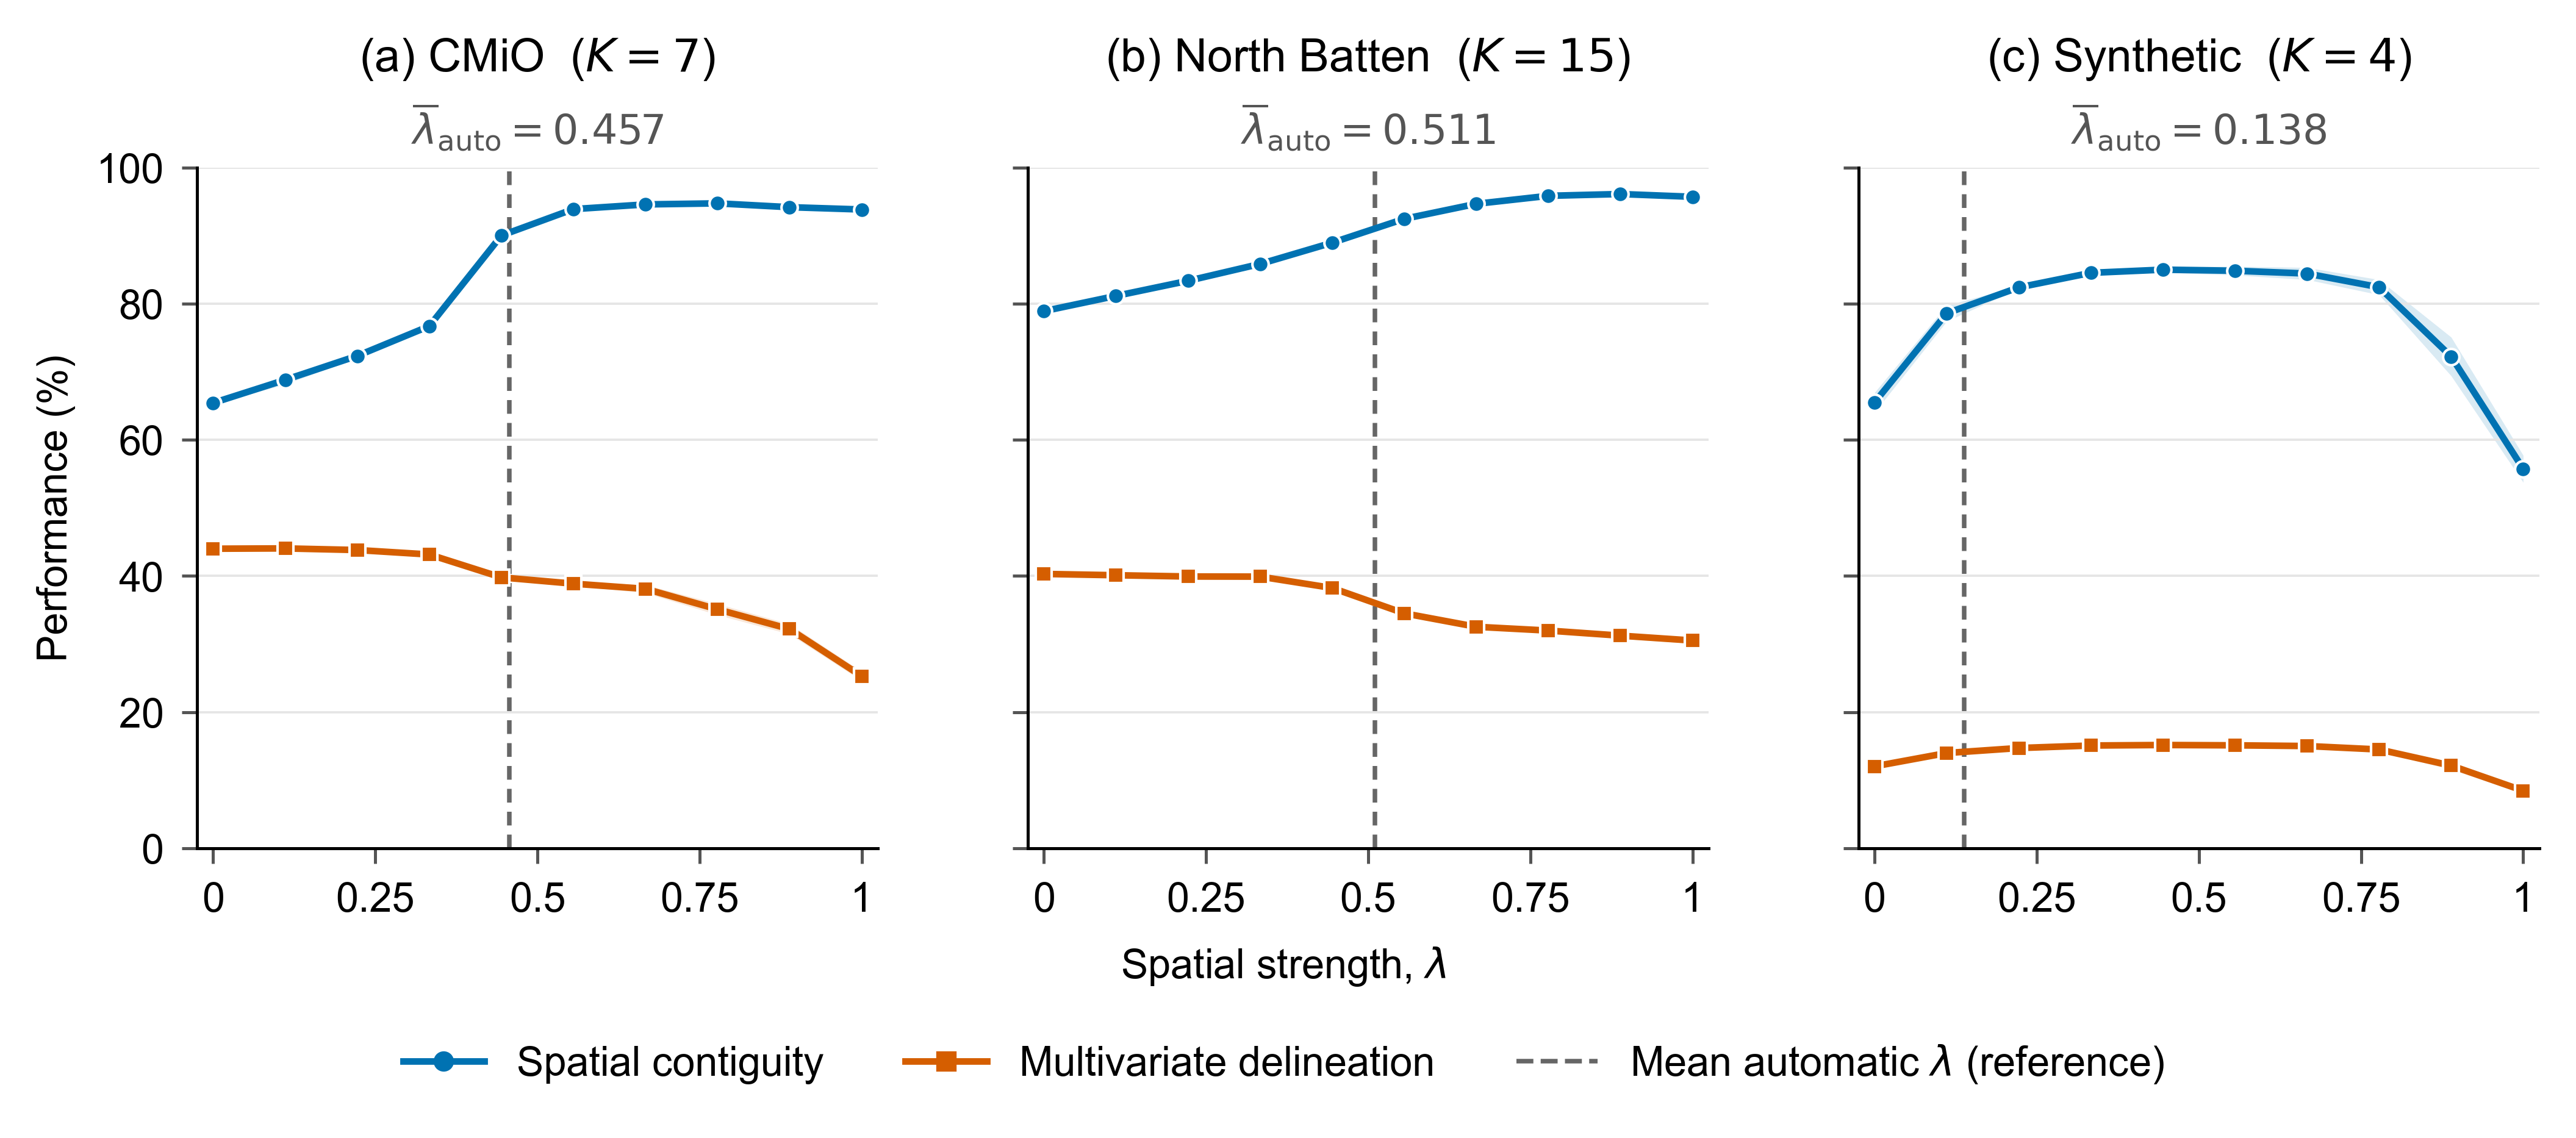

In [35]:
paper_style = {
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 'font.size': 8,
    'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 8,
    'ytick.labelsize': 8, 'axes.linewidth': .6, 'axes.grid': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 600, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}
with plt.rc_context(paper_style):
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 3.05), sharex=True, sharey=True)
    fig.subplots_adjust(left=.075, right=.99, bottom=.25, top=.86, wspace=.16)
    for index, (ax, name) in enumerate(zip(axes, datasets)):
        part = lambda_summary.loc[lambda_summary.dataset == name].sort_values('lambda_value')
        for metric, color, marker in [('spatial', '#0072B2', 'o'),
                                       ('multivariate', '#D55E00', 's')]:
            ax.fill_between(part.lambda_value.to_numpy(),
                            part[f'{metric}_ci_low'].to_numpy(),
                            part[f'{metric}_ci_high'].to_numpy(),
                            color=color, alpha=.15, linewidth=0, zorder=1)
            ax.plot(part.lambda_value, part[f'{metric}_mean'], color=color, marker=marker,
                    markersize=3.2, markeredgecolor='white', markeredgewidth=.5, linewidth=1.3)
        automatic = float(automatic_reference.loc[name, 'mean'])
        ax.axvline(automatic, color='#666666', ls=(0, (3, 2)), lw=.9, zorder=1)
        ax.set_title(f'({chr(97 + index)}) {name}  ($K={int(part.K.iloc[0])}$)', pad=19)
        ax.text(.5, 1.035, rf'$\overline{{\lambda}}_{{\mathrm{{auto}}}}={automatic:.3f}$',
                transform=ax.transAxes, ha='center', fontsize=8, color='#555555')
        ax.set(xlim=(-.025, 1.025), ylim=(0, 100), xticks=[0, .25, .5, .75, 1],
               yticks=np.arange(0, 101, 20))
        ax.set_xticklabels(['0', '0.25', '0.5', '0.75', '1'])
        ax.set_box_aspect(1)
        ax.grid(axis='y', color='#E5E5E5', linewidth=.45)
        ax.tick_params(length=3, width=.6, color='#555555')
    axes[0].set_ylabel('Performance (%)')
    fig.supxlabel(r'Spatial strength, $\lambda$', y=.125, fontsize=8)
    handles = [Line2D([], [], color='#0072B2', marker='o', markersize=3, lw=1.3,
                      label='Spatial contiguity'),
               Line2D([], [], color='#D55E00', marker='s', markersize=3, lw=1.3,
                      label='Multivariate delineation'),
               Line2D([], [], color='#666666', ls='--', lw=.9, label=r'Mean automatic $\lambda$ (reference)')]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .005),
               ncol=3, frameon=False, fontsize=8, handlelength=2)
    display(fig)
    plt.close(fig)

## 6. Interpretation of the lambda sweep

The table compares fixed lambda 0 with fixed lambda 1 using means across seeds. Endpoint changes are calculated within each seed before summarizing their mean and 95% Student-t confidence interval, preserving the paired design. Positive values indicate an increase from lambda 0 to lambda 1. The table also reports mean inferred lambda for reference and mean endpoint target shares.

Use both curves and their pointwise confidence bands to assess the sampled trade-offs relative to the automatic-lambda reference line. The line indicates a mean inferred parameter value, not a separately measured performance result. Dataset-dependent lambda values demonstrate responsiveness to the input data; they do not by themselves establish an optimal trade-off. These intervals describe algorithm-seed uncertainty in the means for fixed datasets.


In [36]:
comparison = []
for name in datasets:
    part = lambda_results.loc[lambda_results.dataset == name]
    zero = part.loc[part.lambda_value == 0.0].set_index('seed').sort_index()
    one = part.loc[part.lambda_value == 1.0].set_index('seed').sort_index()
    assert zero.index.equals(one.index) and len(zero) == len(SEEDS)
    row = {'Dataset': name, 'K': int(one.K.iloc[0]), 'Seeds': len(SEEDS),
           'Mean automatic lambda (reference)': automatic_reference.loc[name, 'mean'],
           'Mean target share: lambda 0': zero.target_share.mean(),
           'Mean target share: lambda 1': one.target_share.mean()}
    for metric, label in [('spatial', 'Spatial'), ('multivariate', 'Multivariate')]:
        change = summarize_mean(one[metric] - zero[metric])
        row.update({f'{label}: lambda 0 mean (%)': zero[metric].mean(),
                    f'{label}: lambda 1 mean (%)': one[metric].mean(),
                    f'{label}: mean change (pp)': change['mean'],
                    f'{label}: change 95% CI lower (pp)': change['ci_low'],
                    f'{label}: change 95% CI upper (pp)': change['ci_high']})
    comparison.append(row)
sweep_comparison = pd.DataFrame(comparison).set_index('Dataset')
display(sweep_comparison.round(3))


,K,Seeds,Mean automatic lambda (reference),Mean target share: lambda 0,Mean target share: lambda 1,Spatial: lambda 0 mean (%),Spatial: lambda 1 mean (%),Spatial: mean change (pp),Spatial: change 95% CI lower (pp),Spatial: change 95% CI upper (pp),Multivariate: lambda 0 mean (%),Multivariate: lambda 1 mean (%),Multivariate: mean change (pp),Multivariate: change 95% CI lower (pp),Multivariate: change 95% CI upper (pp)
Dataset,,,,,,,,,,,,,,,
CMiO,7,30,0.457,0.0,1.0,65.422,93.834,28.412,28.085,28.739,44.007,25.294,-18.713,-19.408,-18.018
North Batten,15,30,0.511,0.0,1.0,78.909,95.700,16.791,16.543,17.038,40.302,30.525,-9.777,-10.220,-9.334
Synthetic,4,30,0.138,0.0,1.0,65.517,55.741,-9.775,-12.312,-7.239,12.047,8.460,-3.586,-3.990,-3.182
